# Practical Lab 1: Predictive Maintenance with Linear Regression-Based Alerts

This notebook implements a predictive maintenance system using industrial current data.

## Step 1: Import Libraries

In [1]:
import os
from pathlib import Path

import pandas as pd
import psycopg2

from dotenv import load_dotenv

## Prepare Clean Training Data

The cleaned CSV file is loaded and duplicate records are removed before uploading the final training dataset to Neon PostgreSQL.

In [2]:
from pathlib import Path
import pandas as pd

# Detect project root
if Path.cwd().name.lower() == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

# Path to cleaned CSV
clean_csv_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "RMBR4-2_cleaned.csv"
)

# Load cleaned CSV
clean_df = pd.read_csv(clean_csv_path)

print("Rows before duplicate removal:", len(clean_df))

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

print("Rows after duplicate removal:", len(clean_df))

clean_df.head()

Rows before duplicate removal: 39672
Rows after duplicate removal: 39672


,Trait,Axis #1,Axis #2,Axis #3,Axis #4,Axis #5,Axis #6,Axis #7,Axis #8,Time
0,current,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022-10-17 12:18:23.660000+00:00
1,current,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022-10-17 12:18:25.472000+00:00
2,current,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022-10-17 12:18:27.348000+00:00
3,current,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022-10-17 12:18:29.222000+00:00
4,current,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022-10-17 12:18:31.117000+00:00


### Time Conversion 

In [3]:
clean_df["Time"] = pd.to_datetime(
    clean_df["Time"],
    format="mixed",
    utc=True
)

print("Time conversion successful!")

clean_df[["Time"]].head()

Time conversion successful!


,Time
0,2022-10-17 12:18:23.660000+00:00
1,2022-10-17 12:18:25.472000+00:00
2,2022-10-17 12:18:27.348000+00:00
3,2022-10-17 12:18:29.222000+00:00
4,2022-10-17 12:18:31.117000+00:00


In [4]:
import os
from pathlib import Path

import psycopg2
from dotenv import load_dotenv

# Find project root
if Path.cwd().name.lower() == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

# Load .env
env_path = PROJECT_ROOT / ".env"

print("Looking for .env here:")
print(env_path)

load_dotenv(env_path)

DATABASE_URL = os.getenv("DATABASE_URL")

if DATABASE_URL is None:
    raise ValueError("DATABASE_URL was not found in the .env file.")

print("DATABASE_URL loaded successfully.")

Looking for .env here:
c:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\.env
DATABASE_URL loaded successfully.


## Replace Database Training Data with Clean Dataset

The previous records in the `robot_measurements` table contained duplicated data.

The existing database records are removed and replaced with the cleaned training dataset.

In [5]:
from psycopg2.extras import execute_values

columns_to_upload = [
    "Trait",
    "Axis #1", "Axis #2", "Axis #3", "Axis #4",
    "Axis #5", "Axis #6", "Axis #7", "Axis #8",
    "Time"
]

upload_df = clean_df[columns_to_upload].copy()

connection = psycopg2.connect(DATABASE_URL)
cursor = connection.cursor()

cursor.execute(
    "TRUNCATE TABLE robot_measurements RESTART IDENTITY;"
)

values = [
    (
        row["Trait"],
        row["Axis #1"],
        row["Axis #2"],
        row["Axis #3"],
        row["Axis #4"],
        row["Axis #5"],
        row["Axis #6"],
        row["Axis #7"],
        row["Axis #8"],
        row["Time"]
    )
    for _, row in upload_df.iterrows()
]

insert_query = """
INSERT INTO robot_measurements (
    trait,
    axis_1,
    axis_2,
    axis_3,
    axis_4,
    axis_5,
    axis_6,
    axis_7,
    axis_8,
    recorded_at
)
VALUES %s
"""

execute_values(
    cursor,
    insert_query,
    values,
    page_size=1000
)

connection.commit()

cursor.close()
connection.close()

print("Clean training data uploaded successfully!")
print("Rows uploaded:", len(upload_df))

Clean training data uploaded successfully!
Rows uploaded: 39672


## Linear Regression Model - Axis #1

A univariate Linear Regression model is trained using Time as the independent variable and Axis #1 current as the dependent variable.

The model will be used to estimate the expected current value and later calculate residuals for anomaly detection.

In [6]:
import os
from pathlib import Path

import pandas as pd
import psycopg2

from dotenv import load_dotenv
from sklearn.linear_model import LinearRegression


# Project folder
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "notebooks"
    else Path.cwd()
)

# Load database URL
load_dotenv(PROJECT_ROOT / ".env")
DATABASE_URL = os.getenv("DATABASE_URL")


# Connect directly with psycopg2
connection = psycopg2.connect(DATABASE_URL)

query = """
SELECT *
FROM robot_measurements
ORDER BY recorded_at;
"""

train_df = pd.read_sql_query(query, connection)

connection.close()

print("Rows loaded:", len(train_df))


# Prepare time
train_df["recorded_at"] = pd.to_datetime(
    train_df["recorded_at"],
    utc=True
)

train_df["time_seconds"] = (
    train_df["recorded_at"] -
    train_df["recorded_at"].min()
).dt.total_seconds()


C:\Users\admin\AppData\Local\Temp\ipykernel_32604\944814165.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  train_df = pd.read_sql_query(query, connection)


Rows loaded: 39672


## Checking if there is dublicated rows

In [7]:
connection = psycopg2.connect(DATABASE_URL)
cursor = connection.cursor()

cursor.execute("""
SELECT COALESCE(SUM(cnt - 1), 0)
FROM (
    SELECT COUNT(*) AS cnt
    FROM robot_measurements
    GROUP BY
        trait,
        axis_1, axis_2, axis_3, axis_4,
        axis_5, axis_6, axis_7, axis_8,
        recorded_at
    HAVING COUNT(*) > 1
) duplicates;
""")

duplicate_count = cursor.fetchone()[0]

cursor.close()
connection.close()

print("Duplicate rows in Neon:", duplicate_count)

Duplicate rows in Neon: 0


## Identify Robot Operating State

Zero-current measurements are valid observations because they represent periods when the robot is stopped.

Instead of deleting these measurements, the data is divided into two operating states:

- `STOPPED`: all eight axes are zero
- `RUNNING`: at least one axis has a non-zero current

This keeps the stopped periods in the dataset while allowing the regression models to represent current behaviour during robot operation.

In [8]:
import numpy as np
axes = [
    "axis_1", "axis_2", "axis_3", "axis_4",
    "axis_5", "axis_6", "axis_7", "axis_8"
]

train_df["robot_state"] = np.where(
    (train_df[axes] == 0).all(axis=1),
    "STOPPED",
    "RUNNING"
)

print(train_df["robot_state"].value_counts())

running_df = train_df[
    train_df["robot_state"] == "RUNNING"
].copy()

robot_state
STOPPED    25487
RUNNING    14185
Name: count, dtype: int64


## Train Linear Regression Models Using Active Robot Data

The Linear Regression models are trained only on periods when the robot is active.

A separate model is fitted for each axis using elapsed time as the input variable.

In [9]:
from sklearn.linear_model import LinearRegression

models = {}

X = running_df[["time_seconds"]]

for axis in axes:

    y = running_df[axis]

    model = LinearRegression()
    model.fit(X, y)

    models[axis] = model

    print(
        axis,
        "| Slope:", model.coef_[0],
        "| Intercept:", model.intercept_
    )

axis_1 | Slope: -7.294771916269537e-07 | Intercept: 2.059558686060432
axis_2 | Slope: 3.922947800160544e-06 | Intercept: 9.94530020816013
axis_3 | Slope: -3.1000095411099976e-06 | Intercept: 7.706927217021061
axis_4 | Slope: 7.069931736127925e-07 | Intercept: 1.7056974203780106
axis_5 | Slope: -3.110900340744172e-07 | Intercept: 2.6822852217377804
axis_6 | Slope: 9.509226405695125e-07 | Intercept: 1.637563972298053
axis_7 | Slope: 1.0135215284316927e-06 | Intercept: 2.39213740258929
axis_8 | Slope: 1.732860679422401e-07 | Intercept: 0.2787825570826755


## Residual Analysis for Active Robot Data

Residuals are calculated as the difference between the actual current and the predicted current.

Positive residuals indicate that the observed current is above the expected regression value.

In [10]:
for axis in axes:

    # Default prediction for stopped robot
    train_df[f"{axis}_predicted"] = 0.0

    # Regression prediction only while robot is running
    running_mask = train_df["robot_state"] == "RUNNING"

    train_df.loc[
        running_mask,
        f"{axis}_predicted"
    ] = models[axis].predict(
        train_df.loc[running_mask, ["time_seconds"]]
    )

    # Residual = Actual - Predicted
    train_df[f"{axis}_residual"] = (
        train_df[axis]
        - train_df[f"{axis}_predicted"]
    )

print("State-aware residuals calculated successfully.")

State-aware residuals calculated successfully.


## Residual Distribution Analysis

Residual distributions are visualized for the RUNNING state to understand the spread of deviations from the regression predictions.

The STOPPED state is not included in this plot because its expected current and residual are both zero by design.

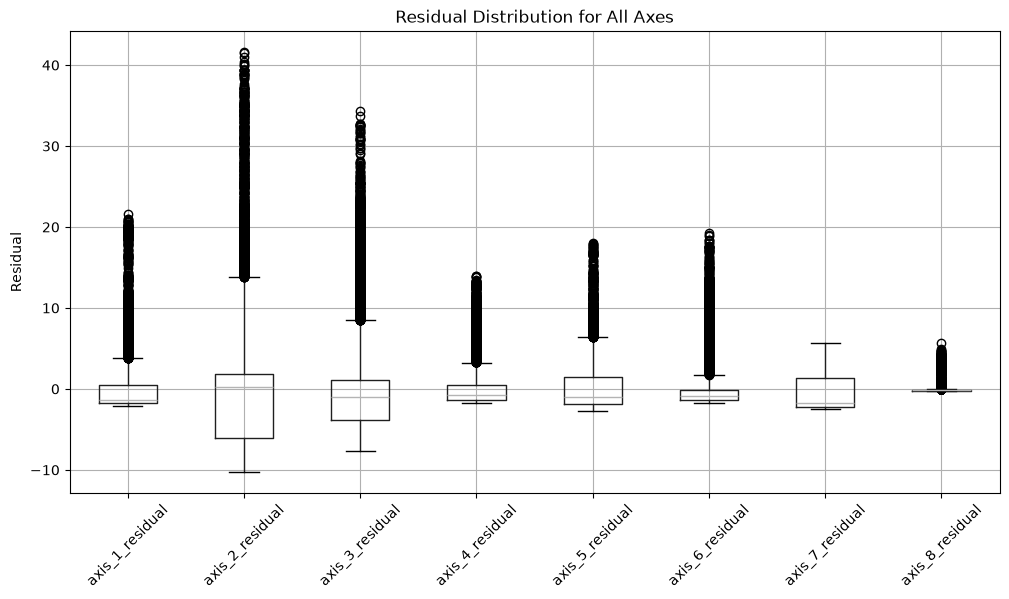

In [11]:
import matplotlib.pyplot as plt

residual_cols = [
    f"{axis}_residual"
    for axis in axes
]

running_residuals = train_df.loc[
    train_df["robot_state"] == "RUNNING",
    residual_cols
]

plt.figure(figsize=(12, 6))

running_residuals.boxplot()

plt.title("Residual Distribution for All Axes")
plt.ylabel("Residual")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

## Regression Models for All Axes

The observed current values are plotted against elapsed time together with the fitted Linear Regression line for each axis.

Only RUNNING-state measurements are used to fit the regression models, while STOPPED periods remain represented separately by the operating-state logic.

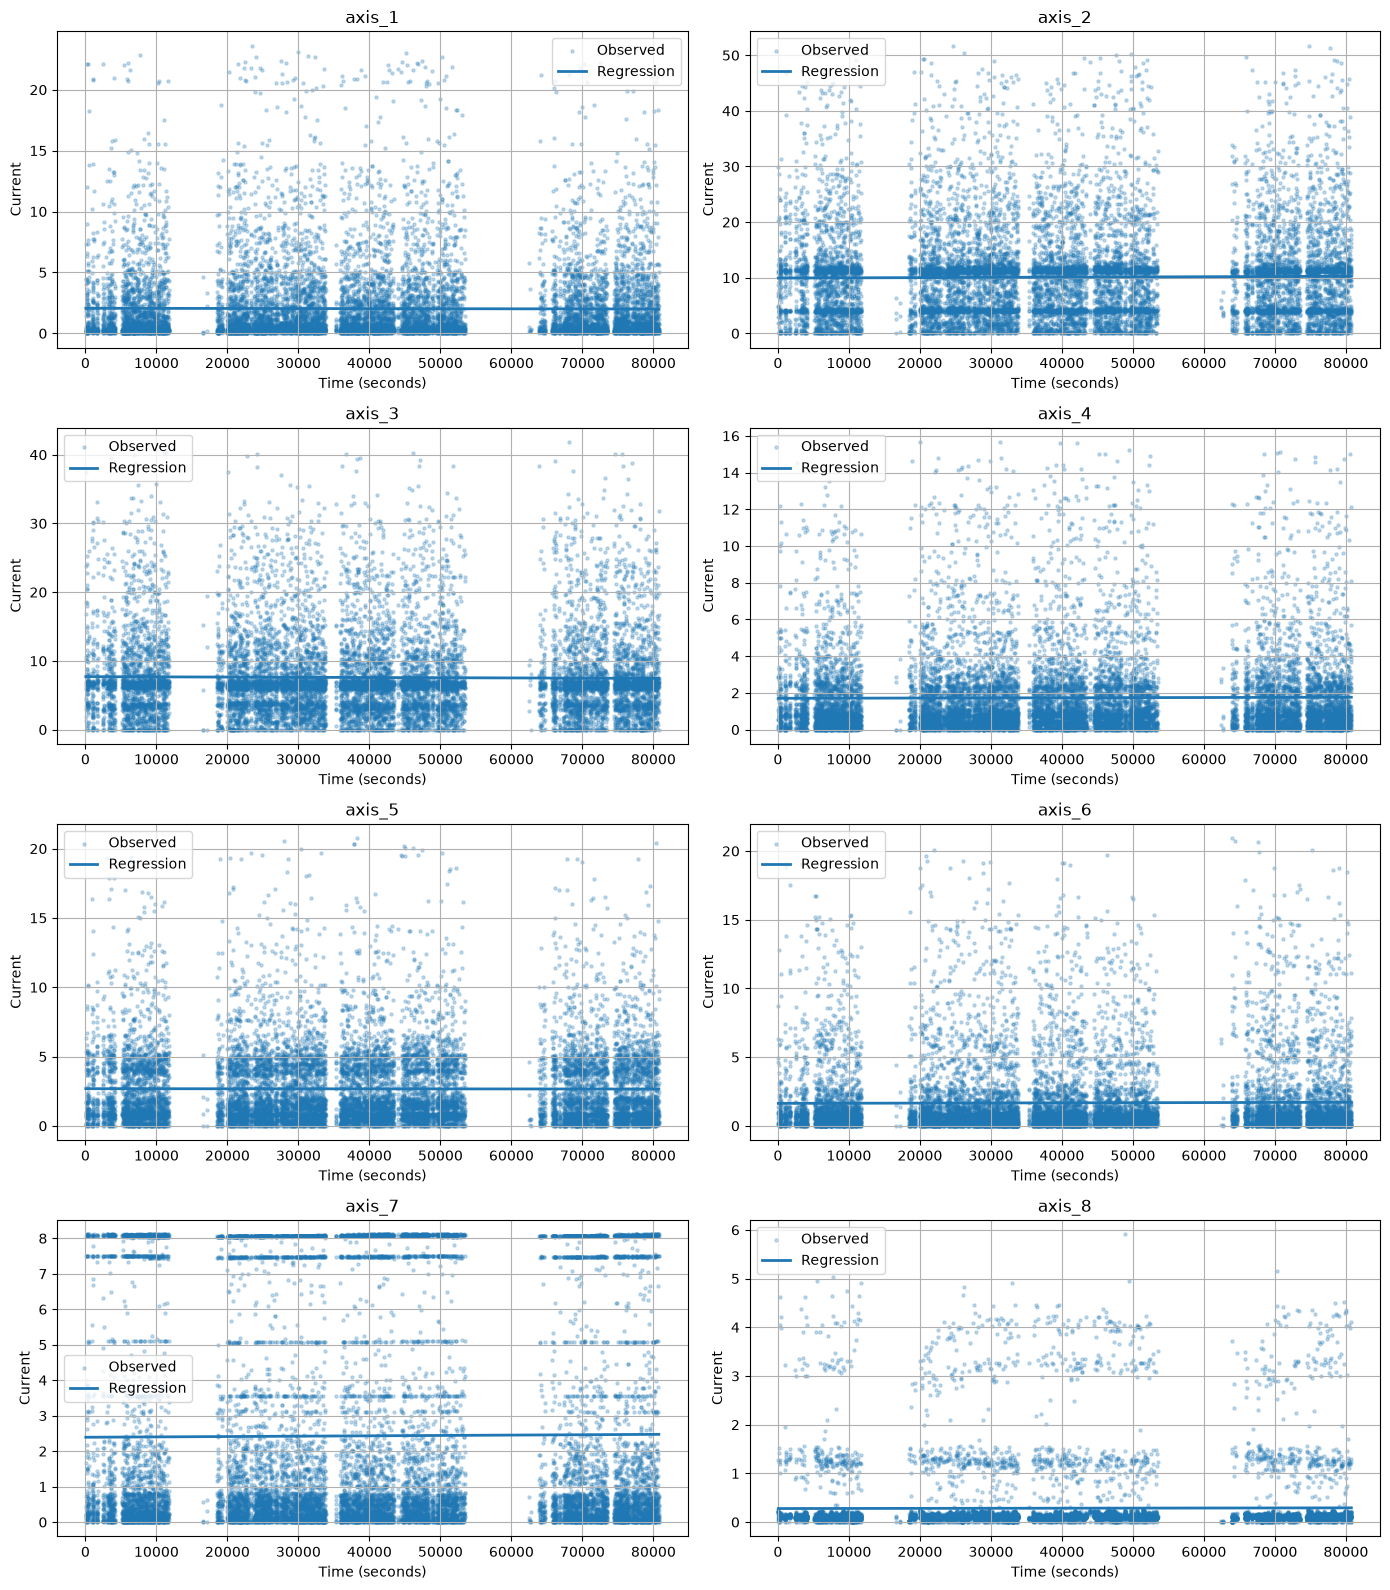

In [12]:
fig, plot_axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, axis in zip(plot_axes.flat, axes):

    ax.scatter(
        running_df["time_seconds"],
        running_df[axis],
        s=5,
        alpha=0.25,
        label="Observed"
    )

    sorted_df = running_df.sort_values("time_seconds")

    ax.plot(
        sorted_df["time_seconds"],
        models[axis].predict(sorted_df[["time_seconds"]]),
        linewidth=2,
        label="Regression"
    )

    ax.set_title(axis)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Current")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Regression Interpretation

The regression plots show that the long-term linear trend is relatively small for most axes, as indicated by the near-horizontal regression lines.

However, the observed current measurements show substantial variability around the expected regression values. These deviations are captured by the residuals and are therefore more useful for predictive-maintenance anomaly detection.

The robot's STOPPED periods are handled separately through the operating-state logic and are not treated as abnormal current measurements.

## Threshold Discovery

Positive residuals are analyzed to determine suitable Alert and Error thresholds.

- MinC: Alert threshold
- MaxC: Error threshold

In [13]:
threshold_summary = []

for axis in axes:
    residual_col = f"{axis}_residual"

    positive_residuals = train_df.loc[
        train_df[residual_col] > 0,
        residual_col
    ]

    threshold_summary.append({
        "axis": axis,
        "p95": positive_residuals.quantile(0.95),
        "p99": positive_residuals.quantile(0.99)
    })

threshold_df = pd.DataFrame(threshold_summary)

threshold_df

,axis,p95,p99
0,axis_1,11.633508,19.522795
1,axis_2,22.116127,34.945784
2,axis_3,20.663610,26.825581
3,axis_4,9.024384,11.885165
4,axis_5,8.563118,14.007147
5,axis_6,11.787657,15.604415
6,axis_7,5.684811,5.705384
7,axis_8,3.834715,4.211080


## Selected Alert and Error Thresholds

The 95th percentile of positive residuals is used as the Alert threshold (`MinC`).

The 99th percentile of positive residuals is used as the Error threshold (`MaxC`).

Separate thresholds are used for each axis because the current ranges and residual distributions differ between axes.

In [14]:
thresholds = {}

for _, row in threshold_df.iterrows():
    thresholds[row["axis"]] = {
        "MinC": row["p95"],
        "MaxC": row["p99"]
    }

thresholds

{'axis_1': {'MinC': 11.63350800504759, 'MaxC': 19.522794798442263},
 'axis_2': {'MinC': 22.11612652511847, 'MaxC': 34.94578431405156},
 'axis_3': {'MinC': 20.663609657828708, 'MaxC': 26.825581060760978},
 'axis_4': {'MinC': 9.024384306666411, 'MaxC': 11.885165208427031},
 'axis_5': {'MinC': 8.563118416261698, 'MaxC': 14.007147023113546},
 'axis_6': {'MinC': 11.787656616258746, 'MaxC': 15.604414772803844},
 'axis_7': {'MinC': 5.684810947576462, 'MaxC': 5.70538389642171},
 'axis_8': {'MinC': 3.834715265213058, 'MaxC': 4.211079988410747}}

## Time Threshold (T)

The median sampling interval of the training stream is approximately 1.891 seconds.

A time threshold of `T = 6 seconds` was selected, which corresponds to approximately three sampling intervals.

This requires an abnormal deviation to persist over multiple consecutive observations before an Alert or Error is confirmed, reducing the effect of short-lived spikes.

In [15]:
sampling_intervals = (
    train_df["recorded_at"]
    .sort_values()
    .drop_duplicates()
    .diff()
    .dt.total_seconds()
    .dropna()
)

print("Median sampling interval:", sampling_intervals.median())
print("Mean sampling interval:", sampling_intervals.mean())
print("Minimum sampling interval:", sampling_intervals.min())

Median sampling interval: 1.891
Mean sampling interval: 2.0366254442791965
Minimum sampling interval: 1.714


In [16]:
T = 6

print("Selected T:", T, "seconds")

Selected T: 6 seconds


## Generate Synthetic Test Data

The synthetic testing dataset is generated using the trained Linear Regression models and the residual variability observed in the active training data.

The generated data is used as testing data for the predictive maintenance pipeline and is saved automatically as:

`data/generated/synthetic_test.csv`

In [17]:
import sys

sys.path.append(str(PROJECT_ROOT / "src"))

from generate_synthetic_data import generate_synthetic_data

In [18]:
synthetic_training_df = train_df[
    train_df["robot_state"] == "RUNNING"
].copy()

synthetic_df = generate_synthetic_data(
    train_df=synthetic_training_df,
    models=models,
    axes=axes,
    sampling_interval=sampling_intervals.median(),
    project_root=PROJECT_ROOT,
    n_test=500
)

synthetic_df.head()

Synthetic data created successfully.
Rows: 500
Saved to: c:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\data\generated\synthetic_test.csv


,time_seconds,recorded_at,trait,axis_1,axis_2,axis_3,axis_4,axis_5,axis_6,axis_7,axis_8
0,80764.766,2022-10-18 10:44:28.426000+00:00,current,3.604618,17.829877,15.871909,3.503904,0.776616,3.267902,0.000000,1.083103
1,80766.657,2022-10-18 10:44:30.317000+00:00,current,1.554162,25.863872,13.017052,0.529858,2.254638,4.350322,0.000000,0.000000
2,80768.548,2022-10-18 10:44:32.208000+00:00,current,4.092138,0.000000,7.815145,0.000000,0.450067,0.812357,1.210911,0.323051
3,80770.439,2022-10-18 10:44:34.099000+00:00,current,6.918765,14.862146,3.566032,1.755253,1.799407,0.047510,8.238704,0.327051
4,80772.330,2022-10-18 10:44:35.990000+00:00,current,1.244515,4.945804,11.655462,1.382119,0.000000,0.000000,4.173628,0.000000


## Normalize and Standardize Synthetic Test Data

The synthetic test data is normalized and standardized using statistics calculated from the active training dataset.

Training statistics are used to keep the testing transformation consistent with the training data.

In [19]:
for axis in axes:

    train_min = synthetic_training_df[axis].min()
    train_max = synthetic_training_df[axis].max()
    train_mean = synthetic_training_df[axis].mean()
    train_std = synthetic_training_df[axis].std()

    # Min-Max normalization
    synthetic_df[f"{axis}_normalized"] = (
        (synthetic_df[axis] - train_min)
        / (train_max - train_min)
    )

    # Z-score standardization
    synthetic_df[f"{axis}_standardized"] = (
        (synthetic_df[axis] - train_mean)
        / train_std
    )

print("Normalization and standardization completed.")

Normalization and standardization completed.


In [20]:
synthetic_df[
    [
        "axis_1",
        "axis_1_normalized",
        "axis_1_standardized"
    ]
].head()

,axis_1,axis_1_normalized,axis_1_standardized
0,3.604618,0.152678,0.487701
1,1.554162,0.065828,-0.147269
2,4.092138,0.173327,0.638672
3,6.918765,0.293053,1.514001
4,1.244515,0.052713,-0.243158


## Save Processed Synthetic Test Data

The normalized and standardized synthetic testing data is saved to a CSV file.

This ensures that the transformed testing dataset can be reused later during the streaming simulation and anomaly detection stages.

In [21]:
synthetic_path = PROJECT_ROOT / "data" / "generated" / "synthetic_test.csv"

synthetic_df.to_csv(
    synthetic_path,
    index=False
)

print("Updated synthetic data saved.")
print(synthetic_path)

Updated synthetic data saved.
c:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\data\generated\synthetic_test.csv


## Inject Controlled Anomalies into Synthetic Test Data

Controlled abnormal current periods are added to the synthetic test data to test the Alert and Error detection logic.

The anomalies are sustained for longer than the selected time threshold `T = 6 seconds`.

In [22]:
# Five consecutive abnormal records are used.
# The elapsed duration from the first to the fifth record is
# approximately 7.56 seconds, which exceeds T = 6 seconds.

alert_rows = range(100, 105)
error_rows = range(250, 255)

# Axis 1 -> Alert example
for i in alert_rows:
    predicted = models["axis_1"].predict(
        synthetic_df.loc[[i], ["time_seconds"]]
    )[0]

    synthetic_df.loc[i, "axis_1"] = (
        predicted + thresholds["axis_1"]["MinC"] * 1.10
    )

# Axis 2 -> Error example
for i in error_rows:
    predicted = models["axis_2"].predict(
        synthetic_df.loc[[i], ["time_seconds"]]
    )[0]

    synthetic_df.loc[i, "axis_2"] = (
        predicted + thresholds["axis_2"]["MaxC"] * 1.10
    )

print("Controlled anomalies added.")

Controlled anomalies added.


In [23]:
from psycopg2.extras import execute_values

# Only columns needed by synthetic_stream
stream_upload_df = synthetic_df[
    [
        "trait",
        "axis_1", "axis_2", "axis_3", "axis_4",
        "axis_5", "axis_6", "axis_7", "axis_8",
        "recorded_at"
    ]
].copy()

connection = psycopg2.connect(DATABASE_URL)
cursor = connection.cursor()

# This is only the TEST table
cursor.execute(
    "TRUNCATE TABLE synthetic_stream RESTART IDENTITY;"
)

values = [
    (
        row["trait"],
        row["axis_1"],
        row["axis_2"],
        row["axis_3"],
        row["axis_4"],
        row["axis_5"],
        row["axis_6"],
        row["axis_7"],
        row["axis_8"],
        row["recorded_at"]
    )
    for _, row in stream_upload_df.iterrows()
]

insert_query = """
INSERT INTO synthetic_stream (
    trait,
    axis_1, axis_2, axis_3, axis_4,
    axis_5, axis_6, axis_7, axis_8,
    recorded_at
)
VALUES %s
"""

execute_values(
    cursor,
    insert_query,
    values
)

connection.commit()

cursor.close()
connection.close()

print(
    "Final anomaly-injected synthetic data uploaded:",
    len(stream_upload_df)
)

Final anomaly-injected synthetic data uploaded: 500


## Update and Save Synthetic Test Data

After injecting controlled anomalies, normalization and standardization are recalculated using the training data statistics.

The updated synthetic dataset is then saved again for use in streaming and anomaly detection.

In [24]:
for axis in axes:

    train_min = synthetic_training_df[axis].min()
    train_max = synthetic_training_df[axis].max()
    train_mean = synthetic_training_df[axis].mean()
    train_std = synthetic_training_df[axis].std()

    synthetic_df[f"{axis}_normalized"] = (
        (synthetic_df[axis] - train_min)
        / (train_max - train_min)
    )

    synthetic_df[f"{axis}_standardized"] = (
        (synthetic_df[axis] - train_mean)
        / train_std
    )

synthetic_path = (
    PROJECT_ROOT
    / "data"
    / "generated"
    / "synthetic_test.csv"
)

synthetic_df.to_csv(
    synthetic_path,
    index=False
)

print("Synthetic test data updated and saved.")

Synthetic test data updated and saved.


## Streaming Simulation

Synthetic test data is streamed from `data/generated/synthetic_test.csv` into the PostgreSQL `synthetic_stream` table using a separate streaming script.

Each record is inserted sequentially with a short delay (`0.05` seconds) to simulate time-based data streaming. Existing test records are cleared before each run to prevent duplicates.

After streaming, the database table is queried to verify that all 500 synthetic records were successfully loaded.

In [25]:
connection = psycopg2.connect(DATABASE_URL)
cursor = connection.cursor()

cursor.execute("SELECT COUNT(*) FROM synthetic_stream;")
stream_count = cursor.fetchone()[0]

cursor.close()
connection.close()

print("Rows in synthetic_stream:", stream_count)

Rows in synthetic_stream: 500


## Live Predictive Maintenance Monitoring

The monitoring logic is implemented in the external `monitoring.py` module.  
The system processes 500 synthetic records from the `synthetic_stream` database table and evaluates all eight axes using the trained regression models.  
ALERT and ERROR events are confirmed only when abnormal residuals persist for at least 6 seconds.  
The live dashboard displays the latest 45 records, representing approximately 90 seconds of streaming data.

In [26]:
import importlib
import monitoring

importlib.reload(monitoring)

<module 'monitoring' from 'c:\\Users\\admin\\Desktop\\Ai-Fall\\CSCN8010-Foundation Machine Learning Framework\\Week4\\Lab1\\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\\src\\monitoring.py'>

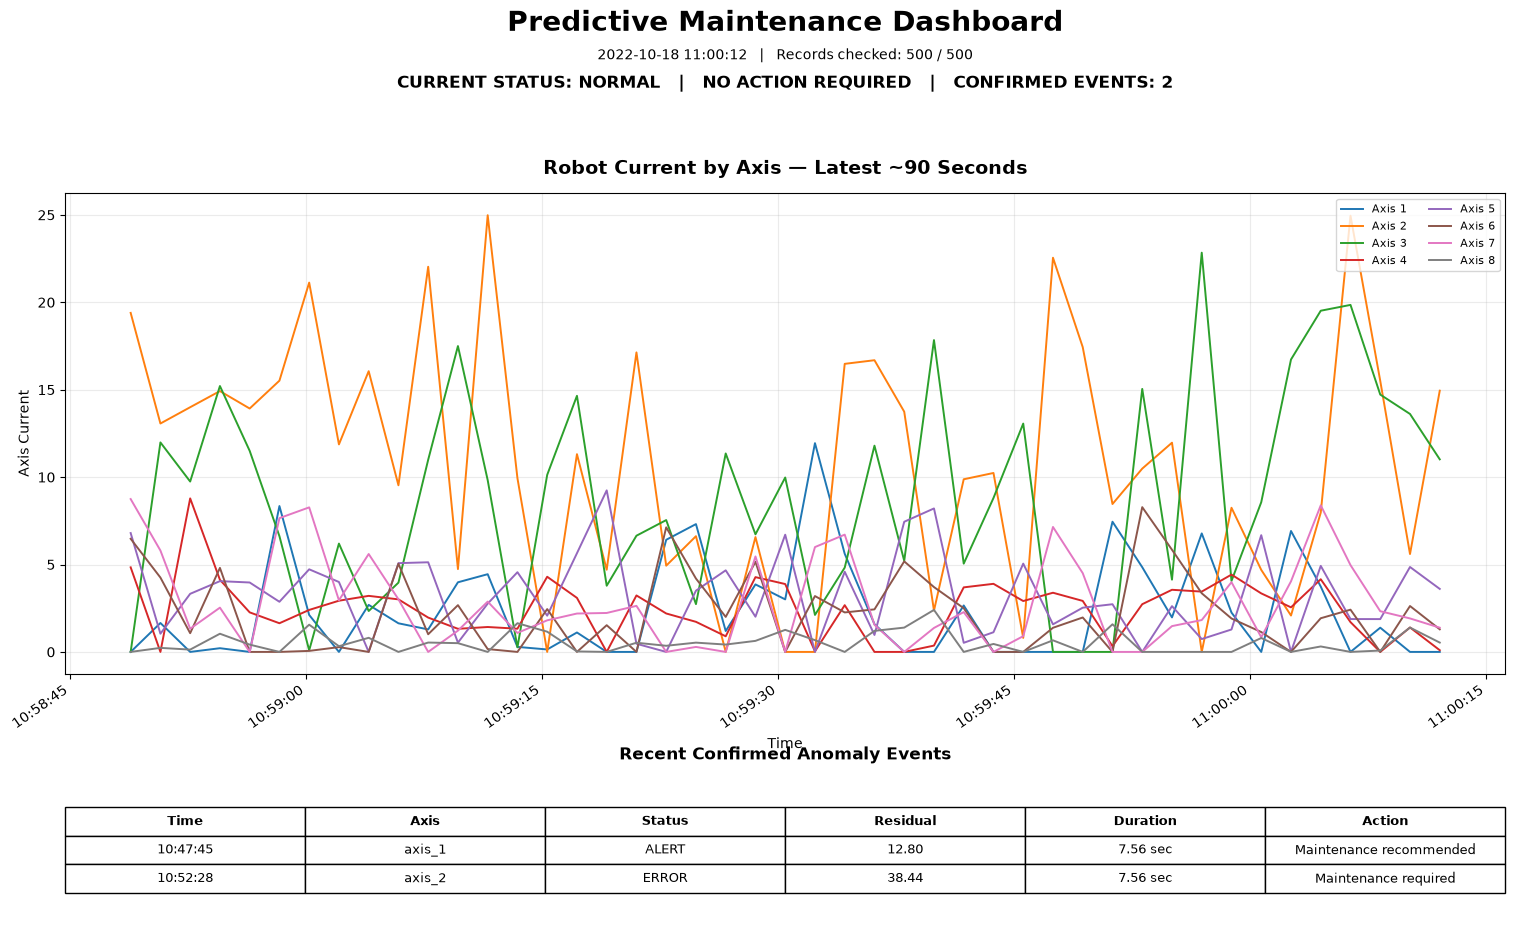

Records checked: 500
Dashboard records: 45
Confirmed events: 2


In [27]:
import importlib
import monitoring

importlib.reload(monitoring)

monitoring_df, events_df, dashboard_df = monitoring.run_monitoring(
    DATABASE_URL,
    train_df,
    models,
    thresholds,
    axes,
    window_size=45,
    sleep_seconds=0.05,
    T=6,
    refresh_every=5,
    limit=500
)

### Confirmed Event Logging

Confirmed ALERT and ERROR events are saved to a CSV log file for maintenance review and traceability.

In [28]:
from pathlib import Path

# Project root
project_root = Path(monitoring.__file__).resolve().parent.parent

# Create logs folder
log_dir = project_root / "logs"
log_dir.mkdir(parents=True, exist_ok=True)

# Log file
log_file = log_dir / "maintenance_events.csv"

# Save confirmed ALERT / ERROR events
events_df.to_csv(
    log_file,
    index=False
)

print("Confirmed events logged:", len(events_df))
print("Log file:", log_file)

display(events_df)

Confirmed events logged: 2
Log file: C:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\logs\maintenance_events.csv


,axis,event,start_time,confirmed_at,duration_seconds,actual,predicted,residual
0,axis_1,ALERT,2022-10-18 10:47:37.526000+00:00,2022-10-18 10:47:45.090000+00:00,7.564,14.797358,2.000499,12.796859
1,axis_2,ERROR,2022-10-18 10:52:21.176000+00:00,2022-10-18 10:52:28.740000+00:00,7.564,48.704383,10.264020,38.440363


## Monitoring Results

The monitoring system processed all 500 synthetic records and evaluated all eight axes using the trained Linear Regression models.

Two confirmed maintenance events were detected:
- **Axis 1:** ALERT
- **Axis 2:** ERROR

Both events remained above their respective residual thresholds for more than the required **6-second persistence period**, so they were confirmed and recorded in the maintenance event log.

The live dashboard displays only the most recent 45 records, representing approximately 90 seconds of streaming data, while the full 500-record sequence is continuously monitored.

## Alert and Error Visualization

Confirmed maintenance events are visualized against the model predictions.  
The detected events are annotated with their duration to show that the abnormal deviation persisted longer than the required 6-second threshold.

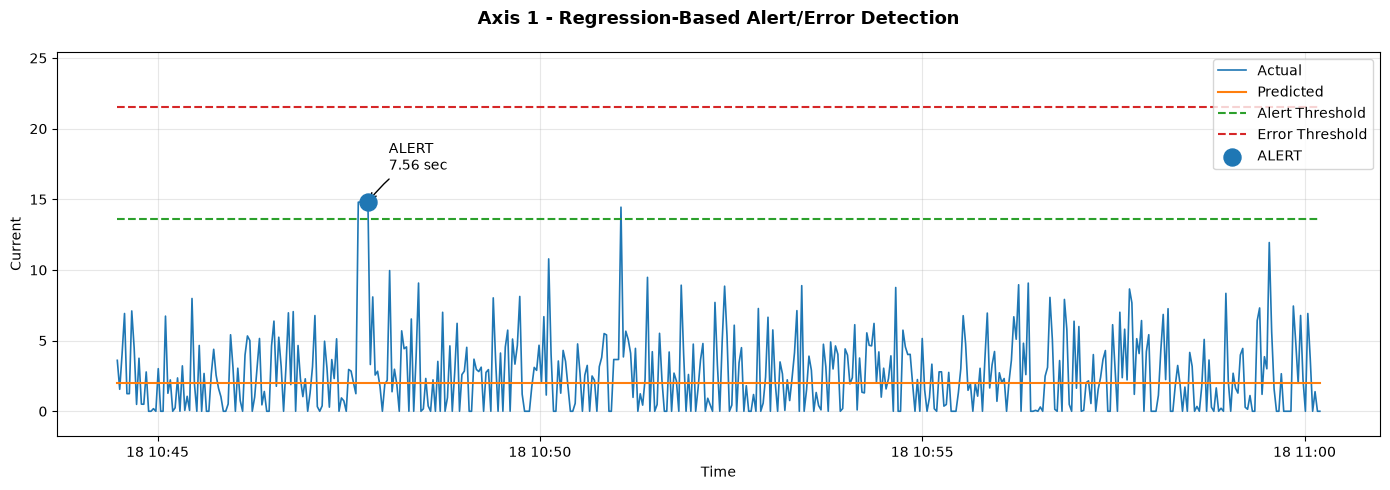

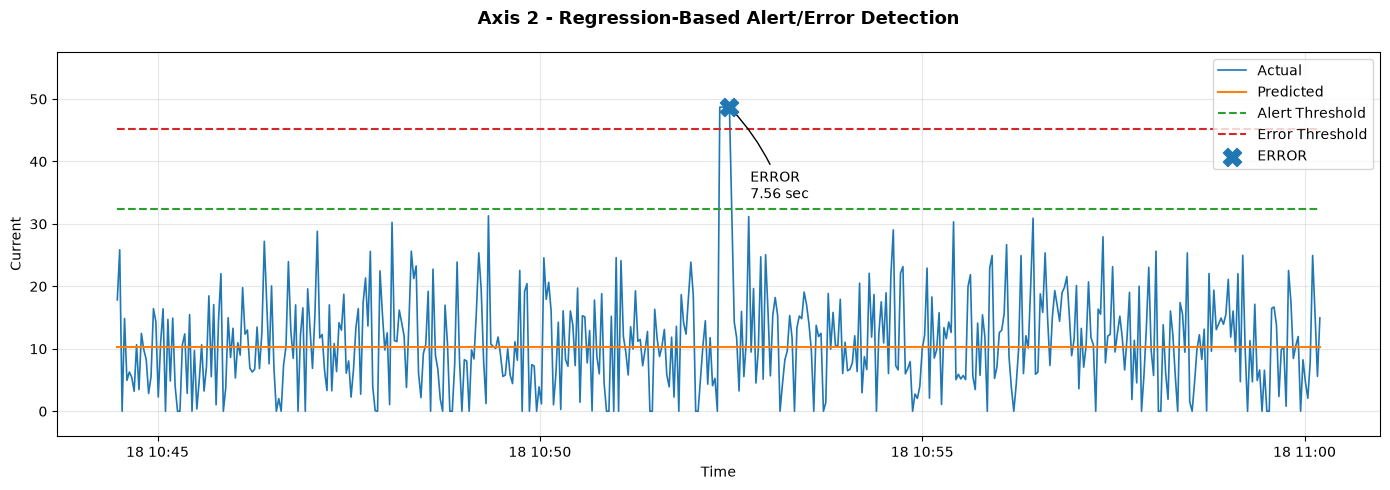

Saved plot files:
c:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\notebooks\plots\axis_1_alert_error_plot.png
c:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\notebooks\plots\axis_2_alert_error_plot.png


In [29]:
from pathlib import Path
import matplotlib.pyplot as plt


# =========================================================
# CREATE PLOTS DIRECTORY
# =========================================================

project_root = Path.cwd()

plots_dir = project_root / "plots"

plots_dir.mkdir(
    parents=True,
    exist_ok=True
)


# =========================================================
# AXES WITH CONFIRMED EVENTS
# =========================================================

event_axes = events_df["axis"].unique()

saved_files = []


# =========================================================
# CREATE EVENT PLOTS
# =========================================================

for axis in event_axes:

    axis_events = events_df[
        events_df["axis"] == axis
    ]

    plt.figure(
        figsize=(14, 5)
    )


    # -----------------------------------------------------
    # ACTUAL VALUES
    # -----------------------------------------------------

    plt.plot(
        monitoring_df["recorded_at"],
        monitoring_df[f"{axis}_actual"],
        label="Actual",
        linewidth=1.2
    )


    # -----------------------------------------------------
    # PREDICTED REGRESSION VALUES
    # -----------------------------------------------------

    plt.plot(
        monitoring_df["recorded_at"],
        monitoring_df[f"{axis}_predicted"],
        label="Predicted",
        linewidth=1.5
    )


    # -----------------------------------------------------
    # ALERT THRESHOLD
    # -----------------------------------------------------

    plt.plot(
        monitoring_df["recorded_at"],
        (
            monitoring_df[f"{axis}_predicted"]
            + thresholds[axis]["MinC"]
        ),
        linestyle="--",
        label="Alert Threshold"
    )


    # -----------------------------------------------------
    # ERROR THRESHOLD
    # -----------------------------------------------------

    plt.plot(
        monitoring_df["recorded_at"],
        (
            monitoring_df[f"{axis}_predicted"]
            + thresholds[axis]["MaxC"]
        ),
        linestyle="--",
        label="Error Threshold"
    )


    # =====================================================
    # CONFIRMED EVENTS
    # =====================================================

    for _, event in axis_events.iterrows():

        event_time = event["confirmed_at"]

        event_row = monitoring_df[
            monitoring_df["recorded_at"]
            == event_time
        ]


        if not event_row.empty:

            event_value = event_row.iloc[0][
                f"{axis}_actual"
            ]


            # -------------------------------------------------
            # EVENT MARKER
            # -------------------------------------------------

            if event["event"] == "ERROR":

                marker = "X"
                marker_size = 170

                # Put ERROR annotation below point
                annotation_offset = (
                    15,
                    -45
                )

                vertical_alignment = "top"

            else:

                marker = "o"
                marker_size = 150

                # Put ALERT annotation above point
                annotation_offset = (
                    15,
                    20
                )

                vertical_alignment = "bottom"


            plt.scatter(
                event_time,
                event_value,
                marker=marker,
                s=marker_size,
                zorder=10,
                label=event["event"]
            )


            # -------------------------------------------------
            # EVENT ANNOTATION
            # -------------------------------------------------

            plt.annotate(
                (
                    f'{event["event"]}\n'
                    f'{event["duration_seconds"]:.2f} sec'
                ),
                xy=(
                    event_time,
                    event_value
                ),
                xytext=annotation_offset,
                textcoords="offset points",
                ha="left",
                va=vertical_alignment,
                fontsize=10,
                arrowprops=dict(
                    arrowstyle="->",
                    connectionstyle="arc3,rad=0.1"
                )
            )


    # =====================================================
    # GRAPH FORMATTING
    # =====================================================

    plt.title(
        (
            f"{axis.replace('_', ' ').title()} - "
            "Regression-Based Alert/Error Detection"
        ),
        pad=20,
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel(
        "Time"
    )

    plt.ylabel(
        "Current"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend(
        loc="best"
    )


    # -----------------------------------------------------
    # EXTRA VERTICAL SPACE
    # -----------------------------------------------------

    ymin, ymax = plt.ylim()

    current_range = (
        ymax - ymin
    )

    plt.ylim(
        ymin - current_range * 0.03,
        ymax + current_range * 0.12
    )


    plt.tight_layout()


    # =====================================================
    # SAVE PLOT
    # =====================================================

    file_path = (
        plots_dir
        / f"{axis}_alert_error_plot.png"
    )

    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight"
    )

    saved_files.append(
        file_path
    )


    # =====================================================
    # DISPLAY
    # =====================================================

    plt.show()

    plt.close()


# =========================================================
# SAVED FILE SUMMARY
# =========================================================

print(
    "Saved plot files:"
)

for file_path in saved_files:

    print(
        file_path
    )